In [ ]:
import meep as mp
import matplotlib.pyplot as plt
import numpy as np
from PIL import Image

In [ ]:
# Khởi tao không gian và vật liệu tường bê tông
cell = mp.Vector3(16,16,0)
wall = mp.Medium(index = 2.5)
geometry = [mp.Block(mp.Vector3(1, 10, mp.inf), 
                     center=mp.Vector3(2,0,0), 
                     material = wall)]

In [ ]:
# sources: danh sách nguồn (2 điểm đỏ ở hình dưới)
sources = [mp.Source(mp.ContinuousSource(frequency=2.4),
                     component = mp.Ez,
                     center=mp.Vector3(-1,2,0)),
           mp.Source(mp.ContinuousSource(frequency=2.4),    # nguồn hình sin có tần số 2.4
                     component = mp.Ez,                     # kích thích thành phần điện trường theo trục z
                     center=mp.Vector3(-3,2,0))]            # tọa độ đặt nguồn

sim_env = mp.Simulation(cell_size=cell, 
                    boundary_layers=[mp.PML(1.0)], 
                    geometry=geometry, 
                    sources=sources, 
                    resolution=10)
sim_env.run(until = 200)

-----------
Initializing structure...
time for choose_chunkdivision = 0.000123024 s
Working in 2D dimensions.
Computational cell is 16 x 16 x 0 with resolution 10
     block, center = (2,0,0)
          size (1,10,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.25,6.25,6.25)
time for set_epsilon = 0.0490549 s
-----------
run 0 finished at t = 200.0 (4000 timesteps)


     block, center = (2,0,0)
          size (1,10,1e+20)
          axes (1,0,0), (0,1,0), (0,0,1)
          dielectric constant epsilon diagonal = (6.25,6.25,6.25)


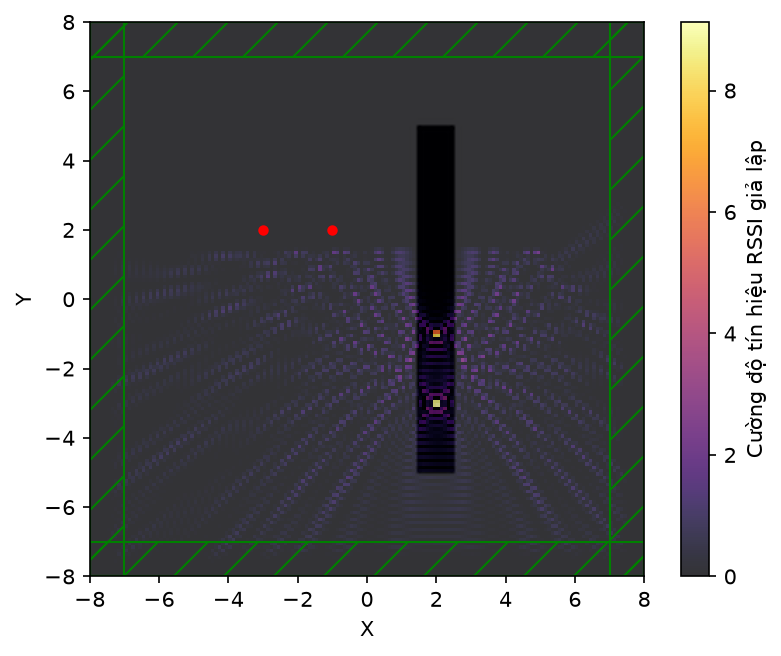

In [19]:
plt.figure(dpi=150)
sim_env.plot2D(output_plane=mp.Volume(center=mp.Vector3(),size = cell))
plt.imshow(np.abs(sim_env.get_array(component=mp.Ez))**2, 
           cmap='inferno', 
           alpha=0.8, 
           origin='lower', 
           extent=[-8,8,-8,8])
plt.colorbar(label="Cường độ tín hiệu RSSI giả lập")
plt.show()